# Bevezetés a Q# programozási nyelvbe

Ez a notebook a diasor futtatható példáit tartalmazza. Ha valaki saját környezetben szeretné futtatni, akkor **legalább 3.10 vagy újabb** Python verzió szükséges. A példák egy része VS Code-ban is futtatható, Microsoft QDK bővítménnyel (a QRE-s példa a notebook végén, illetve a `sparse` szimulátórtól eltérő szimulátorok viszont VS Code-ban sajnos nem használhatók).

Ahhoz, hogy használjuk a `%%qsharp` cellákat, telepítenünk kell a `qdk` csomagot. Csak ezután tudjuk használni!

## 0. Telepítés

A következő cella csak akkor szükséges, ha a QDK még nincs telepítve. A QRE részhez a `qre` extra paraméter szükséges.

In [1]:
# Szükség esetén távolítsd el a kommentjelet, majd indítsd újra a kernelt.
# %pip install --upgrade "qdk[jupyter,qre]"

In [2]:
from qdk import qsharp, code
print("A QDK importja sikerült.")

A QDK importja sikerült.


## 1. Első Q# program: Hello World, klasszikus függvény és kvantumművelet

In [3]:
%%qsharp
operation HelloWorld(): Unit {
    Message("Hello World!");
}

In [4]:
print(qsharp.run("HelloWorld()", shots=1))

Hello World!

[None]


In [5]:
%%qsharp
function ClassicalSquare(x : Int) : Int {
    return x * x;
}

operation QuantumCoin() : Result {
    use q = Qubit();
    H(q);
    return MResetZ(q);
}

In [6]:
print("Négyzet:", qsharp.eval("ClassicalSquare(7)"))
print("Kvantumérme, 20 futtatás:")
print(qsharp.run("QuantumCoin()", shots=20))

Négyzet: 49
Kvantumérme, 20 futtatás:
[One, One, One, One, One, Zero, One, Zero, One, Zero, Zero, One, Zero, One, Zero, One, Zero, Zero, Zero, One]


## 2. Tömbök, módosítható változók és vezérlés

In [7]:
%%qsharp
function Sum(xs : Int[]) : Int {
    mutable total = 0;
    for x in xs {
        set total += x;
    }
    return total;
}

operation RepeatUntilOne(maxTries : Int) : Int {
    mutable tries = 0;
    mutable found = false;
    while not found and tries < maxTries {
        set tries += 1;
        use q = Qubit();
        H(q);
        set found = MResetZ(q) == One;
    }
    return tries;
}

In [8]:
print(qsharp.eval("Sum([10, 20, 30, 40])"))
print(qsharp.run("RepeatUntilOne(20)", shots=10))

100
[2, 1, 5, 4, 2, 3, 1, 5, 1, 1]


## 3. Bell-pár, mérés és diagnosztika

A `Std.Diagnostics.DumpMachine` képes elmenteni/megjeleníti a szimulátor aktuális állapotát. Csak a `sparse` szimulátor esetén használható. A kimentén láthatjuk a nem nulla bázisvektorok komplex amplitúdóit

In [9]:
%%qsharp
import Std.Diagnostics.*;

operation BellPair() : (Result, Result) {
    use (a, b) = (Qubit(), Qubit());
    H(a);
    CNOT(a, b);
    return (MResetZ(a), MResetZ(b));
}

operation DumpBellState() : (Result, Result) {
    use (left, right) = (Qubit(), Qubit());
    H(left);
    CNOT(left, right);
    DumpMachine();
    return (MResetZ(left), MResetZ(right));
}

In [10]:
print("Bell-mérések:")
print(qsharp.run("BellPair()", shots=10))
print("Állapotdump és egy mérés:")
print(qsharp.run("DumpBellState()", shots=1))

Bell-mérések:
[(Zero, Zero), (Zero, Zero), (One, One), (Zero, Zero), (One, One), (One, One), (Zero, Zero), (Zero, Zero), (One, One), (Zero, Zero)]
Állapotdump és egy mérés:


<table class="qs-stateTable">
  <style>
    .qs-stateTable thead tr {
      background-color: var(
        --vscode-list-hoverBackground,
        var(--jp-layout-color1, inherit)
      );
    }
    .qs-stateTable th {
      text-align: left;
      border: none;
    }
    .qs-stateTable tbody {
      pointer-events: none;
    }
    .qs-stateTable tbody td {
      text-align: left;
      border: none;
    }
    .qs-stateTable tbody td span {
      display: inline-block;
    }
    .qs-stateTable tbody tr:nth-child(even) {
      background-color: var(
        --vscode-list-hoverBackground,
        var(--jp-layout-color1, inherit)
      );
    }
  </style>
  <thead>
    <tr>
      <th>Basis State<br />(|𝜓₁…𝜓ₙ⟩)</th>
      <th>Amplitude</th>
      <th>Measurement Probability</th>
      <th colspan="2">Phase</th>
    </tr>
  </thead>
  <tbody>
    <tr>
  <td>
    <span>|00⟩</span>
  </td>
  <td>
    <span>0.7071+0.0000𝑖</span>
  </td>
  <td>
    <progress max="100" value="50.000000000000014"></progress>
    <span>50.0000%</span>
  </td>
  <td style="transform: rotate(0.0000rad)">↑</td>
  <td>
    <span>0.0000</span>
  </td>
</tr>
<tr>
  <td>
    <span>|11⟩</span>
  </td>
  <td>
    <span>0.7071+0.0000𝑖</span>
  </td>
  <td>
    <progress max="100" value="50.000000000000014"></progress>
    <span>50.0000%</span>
  </td>
  <td style="transform: rotate(0.0000rad)">↑</td>
  <td>
    <span>0.0000</span>
  </td>
</tr>

  </tbody>
</table>


$|\psi\rangle = \frac{\sqrt{2}}{2}|00\rangle+\frac{\sqrt{2}}{2}|11\rangle$

[(One, One)]


## 4. Adjungált, vezérelt operációk és a `within ... apply` szerkezet

In [11]:
%%qsharp
operation Prepare(q : Qubit) : Unit is Adj {
    H(q);
    T(q);
    Rz(0.3, q);
}

operation RotateTarget(theta : Double, q : Qubit)
    : Unit is Adj + Ctl {
    Ry(theta, q);
}

operation ApplyPhaseInXBasis(q : Qubit) : Unit is Adj {
    within {
        H(q);
    } apply {
        Rz(0.4, q);
    }
}

operation SpecializationDemo() : Result[] {
    use (control, target) = (Qubit(), Qubit());
    H(control);
    Prepare(target);
    Adjoint Prepare(target);
    Controlled RotateTarget([control], (0.25, target));
    ApplyPhaseInXBasis(target);
    return MResetEachZ([control, target]);
}

In [12]:
qsharp.run("SpecializationDemo()", shots=10)

[[Zero, Zero],
 [Zero, Zero],
 [Zero, Zero],
 [Zero, Zero],
 [Zero, Zero],
 [One, Zero],
 [Zero, Zero],
 [One, Zero],
 [One, Zero],
 [Zero, Zero]]

## 5. Magasabb rendű művelet

In [13]:
%%qsharp
operation ApplyToRegister(
    op : Qubit => Unit,
    qs : Qubit[]
) : Unit {
    for q in qs {
        op(q);
    }
}

operation PutAllInPlus(n : Int) : Result[] {
    use qs = Qubit[n];
    ApplyToRegister(H, qs);
    return MResetEachZ(qs);
}

In [14]:
qsharp.run("PutAllInPlus(4)", shots=10)

[[Zero, Zero, One, Zero],
 [One, Zero, One, Zero],
 [One, Zero, Zero, One],
 [One, One, One, Zero],
 [One, Zero, One, One],
 [Zero, One, One, Zero],
 [Zero, Zero, One, One],
 [Zero, One, Zero, One],
 [Zero, Zero, One, Zero],
 [One, One, Zero, One]]

## 6. GHZ-állapot: lineáris és fa-szerű konstrukció

Mindkét program $n-1$ CNOT-ot használ. Ideális, párhuzamos ütemezés mellett a lineáris konstrukció CNOT-mélysége $n-1$, a fa-szerű konstrukcióé $\lceil\log_2 n \rceil$.

In [15]:
%%qsharp
operation PrepareGhzLinear(n : Int) : Result[] {
    use qs = Qubit[n];
    H(qs[0]);
    for i in 1..n - 1 {
        CNOT(qs[i - 1], qs[i]);
    }
    // T(qs[0]);
    return MResetEachZ(qs);
}

operation PrepareGhzTree(n : Int) : Result[] {
    use qs = Qubit[n];
    H(qs[0]);
    mutable width = 1;
    while width < n {
        for source in 0..width - 1 {
            let target = source + width;
            if target < n {
                CNOT(qs[source], qs[target]);
            }
        }
        set width *= 2;
    }
    return MResetEachZ(qs);
}

## 7. Logikai erőforrások a Microsoft Quantum Resource Estimatorral

Ez a rész már a `qdk[qre]` igényli. A `required_isa.as_frame()` kimenete QDK-verziótól és az alkalmazott transzformációktól függhet.

In [16]:
import qdk

from qdk.qre.application import QSharpApplication

linear_app = QSharpApplication(qdk.code.PrepareGhzLinear, args=(8,))
tree_app = QSharpApplication(qdk.code.PrepareGhzTree, args=(8,))

linear_trace = next(linear_app.enumerate_traces())
tree_trace = next(tree_app.enumerate_traces())

print("Lineáris GHZ szükséges ISA:")
display(linear_trace.required_isa.as_frame())
print("Fa-szerű GHZ szükséges ISA:")
display(tree_trace.required_isa.as_frame())

Lineáris GHZ szükséges ISA:


,encoding,arity
id,,
MEAS_Z,LOGICAL,1


Fa-szerű GHZ szükséges ISA:


,encoding,arity
id,,
MEAS_Z,LOGICAL,1


## 8. Fizikai erőforrásbecslés, ízelítő

A következő cellában definiálunk egy kapukat használó architektúrát, egy felületi kódot a hibajavításhoz és egy round-based magic-state factory modellt. A GHZ állapot előállítása során csak Clifford kapukat használunk, ezért a példában $T$-factory nem fog szerepelni (hogy ez pontosan mit is jelent, azt a következő órán megtudjuk).

In [17]:
from qdk.qre import estimate, PSSPC, LatticeSurgery
from qdk.qre.models import GateBased, SurfaceCode, RoundBasedFactory

# Architektúra definiálása
architecture = GateBased(
    error_rate=1e-4,
    gate_time=100,
    measurement_time=500,
)

# A becslés elkészítése, figyeljük meg, hogy megadjuk a hibás számítás max. valószínűségét
physical_results = estimate(
    linear_app,
    architecture,
    isa_query=SurfaceCode.q() * RoundBasedFactory.q(),
    trace_query=PSSPC.q() * LatticeSurgery.q(),
    max_error=0.01,
)

physical_results.add_qubit_partition_column()
display(physical_results.as_frame())

print("A becslés eredménye:")
print(physical_results[0].source)

# A létrehozott architektúrán elérhető utasítások
architecture.provided_isa(architecture.context()).as_frame()

,qubits,runtime,error,physical_compute_qubits,physical_factory_qubits,physical_memory_qubits
0,425,0 days 00:00:00.000024,0.0006,425,0,0


A becslés eredménye:
LATTICE_SURGERY @ SurfaceCode(crossing_prefactor=0.03, error_correction_threshold=0.01, one_qubit_gate_depth=1, two_qubit_gate_depth=4, code_cycle_override=None, code_cycle_offset=0, distance=3)
  CNOT @ GateBased(error_rate=0.0001, gate_time=100, measurement_time=500, two_qubit_gate_time=100)
  H @ GateBased(error_rate=0.0001, gate_time=100, measurement_time=500, two_qubit_gate_time=100)
  MEAS_Z @ GateBased(error_rate=0.0001, gate_time=100, measurement_time=500, two_qubit_gate_time=100)


,encoding,arity,space,time,error
id,,,,,
PAULI_I,PHYSICAL,1,1,100,0.0001
SQRT_SQRT_X,PHYSICAL,1,1,100,0.0001
SQRT_SQRT_Y_DAG,PHYSICAL,1,1,100,0.0001
S,PHYSICAL,1,1,100,0.0001
SQRT_X_DAG,PHYSICAL,1,1,100,0.0001
MEAS_X,PHYSICAL,1,1,500,0.0001
RZ,PHYSICAL,1,1,100,0.0001
T_DAG,PHYSICAL,1,1,100,0.0001
PAULI_Y,PHYSICAL,1,1,100,0.0001


Nézzünk meg egy kicsit "össztettebb" áramkört:

In [18]:
%%qsharp

import Std.Arithmetic.*;

// Két n-qubites regiszter összeadása egy beépített függvénnyel
operation ProgramAddition(n : Int) : Unit {
    use a = Qubit[n];
    use b = Qubit[n];

    RippleCarryCGIncByLE(a, b);
}

In [19]:
add_app = QSharpApplication(qdk.code.ProgramAddition, args=(8,))

add_trace = next(add_app.enumerate_traces())

print("Szükséges ISA:")
display(add_trace.required_isa.as_frame())

architecture = GateBased(
    error_rate=1e-4,
    gate_time=100,
    measurement_time=500,
)

physical_results = estimate(
    add_app,
    architecture,
    isa_query=SurfaceCode.q() * RoundBasedFactory.q(),
    trace_query=PSSPC.q() * LatticeSurgery.q(),
    max_error=0.01,
)

print("A becslés eredménye:")
display(physical_results.as_frame())

Szükséges ISA:


,encoding,arity
id,,
CCX,LOGICAL,3
MEAS_Z,LOGICAL,1


A becslés eredménye:


,qubits,runtime,error
0,1072,0 days 00:00:00.000084,0.008092


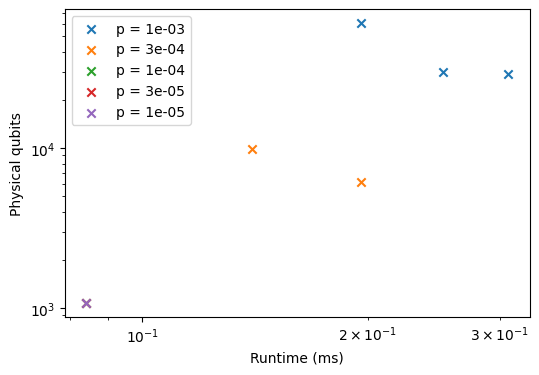

In [20]:
from qdk.qre import plot_estimates
import numpy as np

results = []

# Vizsgáljuk meg, hogy hogyan változik a becslés erdménye, ha módosítjuk a fizikai hibavalószínűség értékét.
for error_rate in np.logspace(-3,-5,5):
    arch = GateBased(error_rate=error_rate, gate_time=100, measurement_time=500)
    results.append(estimate(add_app, arch, isa_query=SurfaceCode.q() * RoundBasedFactory.q(), max_error=0.01, name=f"p = {error_rate:.0e}"))

# Több becslés egyszüttes kirajzolása
plot_estimates(results, figsize=(6, 4), runtime_unit="ms")

## Kiegészítés: Különböző szimulátorok használata

Nézzük meg, hogy megfelelően működnek-e a különböző szimulátorok (a GPU kivételével)!

### Sparse és stabilizer szimulátor

In [21]:
%%qsharp

operation DumpState() : (Result, Result) {
    use (left, right) = (Qubit(), Qubit());
    H(left);
    CNOT(left, right);
    return (MResetZ(left), MResetZ(right));
}

In [22]:
result = qsharp.run("DumpState()", shots=10)
print(result)

[(One, One), (One, One), (Zero, Zero), (One, One), (Zero, Zero), (Zero, Zero), (One, One), (Zero, Zero), (One, One), (One, One)]


In [23]:
result = qsharp.run("DumpState()", type="stabilizer", shots=10)
print(result)

[(Zero, Zero), (One, One), (Zero, Zero), (One, One), (Zero, Zero), (One, One), (Zero, Zero), (One, One), (Zero, Zero), (Zero, Zero)]


### CPU szimulátor

Figyelem, a CPU és GPU szimulátor csak QIR-t képes értelmezni!

Az első példában egy OpenQASM kódot fordítunk le QIR-re, majd az futtatjuk. A másodikban pedig Q# kódot QIR-re és után ezt adjuk át a szimulátornak. A második esetben a cellák sorrendje fontos: Először inicializáljuk a Q# interpretert a megfelelő célprofillal, majd csak ezután futtatjuk a `%%qsharp` cellát és a fordítási lépéseket.

In [24]:
from qdk.openqasm import compile
from qdk.simulation import run_qir

qasm_code = """
include "stdgates.inc";
qubit[2] q;
bit[2] result;
h q[0];
cx q[0], q[1];
result = measure q;
"""

qir = compile(qasm_code)

result = run_qir(
    qir,
    type="cpu",
    shots=10,
)
print(qir)
print(result)

%Result = type opaque
%Qubit = type opaque

@0 = internal constant [4 x i8] c"0_a\00"
@1 = internal constant [6 x i8] c"1_a0r\00"
@2 = internal constant [6 x i8] c"2_a1r\00"

define i64 @ENTRYPOINT__main() #0 {
block_0:
  call void @__quantum__rt__initialize(i8* null)
  call void @__quantum__qis__h__body(%Qubit* inttoptr (i64 0 to %Qubit*))
  call void @__quantum__qis__cx__body(%Qubit* inttoptr (i64 0 to %Qubit*), %Qubit* inttoptr (i64 1 to %Qubit*))
  call void @__quantum__qis__m__body(%Qubit* inttoptr (i64 0 to %Qubit*), %Result* inttoptr (i64 0 to %Result*))
  call void @__quantum__qis__m__body(%Qubit* inttoptr (i64 1 to %Qubit*), %Result* inttoptr (i64 1 to %Result*))
  call void @__quantum__rt__array_record_output(i64 2, i8* getelementptr inbounds ([4 x i8], [4 x i8]* @0, i64 0, i64 0))
  call void @__quantum__rt__result_record_output(%Result* inttoptr (i64 0 to %Result*), i8* getelementptr inbounds ([6 x i8], [6 x i8]* @1, i64 0, i64 0))
  call void @__quantum__rt__result_record_

A sorrend fontos!

In [25]:
from qdk import qsharp
from qdk.simulation import run_qir

qsharp.init(target_profile=qsharp.TargetProfile.Base)

Q# initialized with configuration: {'targetProfile': 'base'}

In [26]:
%%qsharp

operation BellExperiment() : Result[] {
    use qs = Qubit[2];

    H(qs[0]);
    CNOT(qs[0], qs[1]);

    return MResetEachZ(qs);
}

In [27]:
qir = qsharp.compile("BellExperiment()")
result = run_qir(qir, type="cpu", shots=10)

print(result)

[[Zero, Zero], [One, One], [One, One], [Zero, Zero], [One, One], [One, One], [Zero, Zero], [One, One], [Zero, Zero], [Zero, Zero]]


## Rövid feladatok

### 1. Egyszerű ciklus

Írjunk egy Q# függvényt, amely egy egész számokat tartalmazó tömb negatív elemeinek összegét adja vissza.

In [ ]:
%%qsharp
function SumNegative(xs : Int[]) : Int {
    // Egészítsd ki!
}

In [ ]:
qsharp.eval("SumNegative([-2, 3, 0, 5, -1])")

### 2. Bázisválasztás és mérés

Egészítsd ki az alábbi műveletet úgy, hogy:
1. Készítsük el a $\ket{+}$ állapot.
2. A kapott paraméter alapján mérjük meg a $Z$ vagy az $X$-bázisban.
3. Biztonságosan állítsuk vissza qubit állapotát.

In [ ]:
%%qsharp

operation MeasurePreparedPlus(measureInX : Bool) : Result {
    use q = Qubit();

    // Állapot előkészítése

    // Mérés a paraméter alapján

    // Visszaállítás
}

In [ ]:
results = qsharp.run("MeasurePreparedPlus(false)", shots=10)
print(results)
results = qsharp.run("MeasurePreparedPlus(true)", shots=10)
print(results)

### 3. Adjungált művelet

Adott az alábbi művelet:

In [ ]:
%%qsharp

operation Prepare(q : Qubit) : Unit is Adj {
    H(q);
    T(q);
    Rz(0.3, q);
}

Írjunk tesztműveletet, amely:

1. Meghívja a Prepare műveletet.
2. Meghívja az adjungáltját.
3. Megméri a qubitet.

Milyen eredményt kell kapnunk?